# Null of the split-half change

`component_model.ipynb` measures the change of the geometry from session 3 to s as
`[L(s <- 3) - L(s <- s)] + [L(3 <- s) - L(3 <- 3)]` and tests it against 0. With a stable geometry
this is exactly 0 only if the two sessions hold the same information. Here two sessions are simulated
with **the same geometry** and the second with `ratio` times the signal of the first, and the change
is measured as in the real analysis (transfer model). Its mean across simulated participants is the
value the real change should be tested against, for a given signal ratio between sessions.

In [ ]:
import itertools
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import scipy.stats as stats
import PcmPy as pcm
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.models as models

In [3]:
# the geometry: the components of one participant, with the median session-3 weights of the real family fits (L)
fam_comp = ['identity', 'single finger', 'muscle pattern', 'hand use', 'mean deviation']
w        = np.array([0.081, 0.052, 0.005, 0.017, 0.004])
G_dict   = models.make_G_dict(gl.participants[0])
Gc       = np.array([G_dict[c] for c in fam_comp])

M_true = pcm.FixedModel('true', np.einsum('k,kij->ij', w, Gc))   # the geometry of both sessions
M_comp = pcm.ComponentModel('comp', Gc)                          # the component model fitted to each half

# design and noise as in the real data: 10 runs per session, ~800 voxels, median noise variance 0.83
n_run, n_vox, noise = 10, 800, 0.83
cond_vec = np.tile(np.arange(8), n_run)
part_vec = np.repeat(np.arange(n_run), 8)

# signal of the second session relative to the first; real total weight, session 23 / session 3: median 1.2, quartiles 0.75 - 1.84
ratios = [0.5, 0.75, 1, 1.25, 1.5, 2]
n_sim  = 10   # simulated participants per ratio
rng    = np.random.default_rng(0)

In [5]:
rows = []
for ratio, i in itertools.product(ratios, range(n_sim)):
    # two sessions with the same geometry: A (the reference) and B, with `ratio` times the signal of A
    Y = {'A': pcm.sim.make_dataset(M_true, np.array([]), cond_vec, n_channel=n_vox, signal=1,     noise=noise, rng=rng)[0].measurements,
         'B': pcm.sim.make_dataset(M_true, np.array([]), cond_vec, n_channel=n_vox, signal=ratio, noise=noise, rng=rng)[0].measurements}

    # 1. component weights of each half (odd / even runs) of each session -> the G they predict (trace 1)
    G_w = {}
    for sess, half in itertools.product('AB', (0, 1)):
        idx  = part_vec % 2 == half
        data = pcm.dataset.Dataset(Y[sess][idx], obs_descriptors={'cond_vec': cond_vec[idx], 'part_vec': part_vec[idx]})
        _, theta = pcm.fit_model_individ(data, [M_comp], fit_scale=False, fixed_effect='block', verbose=False)
        G_w[sess, half] = models.normalise(np.einsum('k,kij->ij', np.exp(theta[0][:len(fam_comp), 0]), Gc))

    # 2. transfer: each half predicted by the other half's G of each session (only its scale fitted), L(sess <- weight session)
    L = {key: 0 for key in itertools.product('AB', 'AB')}
    for sess, half in itertools.product('AB', (0, 1)):
        idx  = part_vec % 2 == half
        data = pcm.dataset.Dataset(Y[sess][idx], obs_descriptors={'cond_vec': cond_vec[idx], 'part_vec': part_vec[idx]})
        M    = [pcm.ComponentModel(ws, G_w[ws, 1 - half][None]) for ws in 'AB']
        T, _ = pcm.fit_model_individ(data, M, fit_scale=False, fixed_effect='block', verbose=False)
        for ws in 'AB':
            L[sess, ws] += T.likelihood[ws].iloc[0]   # the two halves added up

    # 3. change as in the real analysis: [L(B <- A) - L(B <- B)] + [L(A <- B) - L(A <- A)]
    rows.append({'ratio': ratio, 'sim': i, 'change': (L['B', 'A'] - L['B', 'B']) + (L['A', 'B'] - L['A', 'A'])})

sim = pd.DataFrame(rows)

sim

,ratio,sim,change
0,0.50,0,3.263366
1,0.50,1,-14.711025
2,0.50,2,4.009234
3,0.50,3,-1.322162
4,0.50,4,-8.532079
5,0.50,5,-5.689781
6,0.50,6,-3.997364
7,0.50,7,-1.016871
8,0.50,8,-8.143732
9,0.50,9,-12.909934


## Reading the result: an SNR check, not a change in geometry

Both sessions are generated from **the same G**; only the signal of B is scaled by `ratio`, with the same noise. Any
non-zero change here is therefore a bias of the measure caused by an SNR difference between sessions, not a change in
geometry.

Why it is negative whenever `ratio` ≠ 1: the weaker session's weights are estimated less precisely. Predicting the strong
session with the weak session's G costs a lot of likelihood (the strong data see the estimation errors), while predicting
the weak session with the strong session's G gains little (the weak data are too noisy to tell the difference). The two
don't cancel, so the sum drops slightly below 0, symmetrically for `ratio` and 1 / `ratio` (≈ −½·p·(r + 1/r − 2), with p the
number of free weights).

What to compare: with 50 simulated participants per ratio the bias was about −2 at ratios 0.5 and 2 and about 0 between
0.75 and 1.5 (the real session 23 / session 3 total weight has a median of 1.2, quartiles 0.75 – 1.84), against real
changes of −22 to −78. With fewer simulated participants (`n_sim`) the individual changes are noisy (SD ≈ 5 – 10), so the
means move around; the point is that the bias is a few units at most, far below what the real change shows.

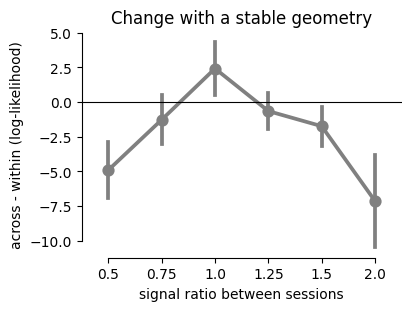

ratio 0.5: mean  -4.91, SE 2.00, t = -2.45, p = 0.036
ratio 0.75: mean  -1.27, SE 1.77, t = -0.72, p = 0.491
ratio 1.0: mean   2.43, SE 1.92, t =  1.26, p = 0.238
ratio 1.25: mean  -0.65, SE 1.31, t = -0.49, p = 0.635
ratio 1.5: mean  -1.74, SE 1.41, t = -1.23, p = 0.250
ratio 2.0: mean  -7.13, SE 3.35, t = -2.13, p = 0.062


In [6]:
fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)

sb.pointplot(data=sim, x='ratio', y='change', errorbar='se', color='grey', ax=ax)
ax.axhline(0, color='k', lw=.8)

sb.despine(ax=ax, trim=True)
ax.set_xlabel('signal ratio between sessions')
ax.set_ylabel('across - within (log-likelihood)')
ax.set_title('Change with a stable geometry')

plt.show()

# mean change with a stable geometry, and whether it differs from 0 (t-test across simulated participants)
for ratio, d in sim.groupby('ratio'):
    t = stats.ttest_1samp(d.change, 0)
    print(f'ratio {ratio}: mean {d.change.mean():6.2f}, SE {d.change.sem():.2f}, t = {t.statistic:5.2f}, p = {t.pvalue:.3f}')